## Content
#### You own supermarket mall and through membership cards , you have some basic data about your customers like Customer ID, age, gender, annual income and spending score.
- #### Spending Score - Score assigned by the mall based on customer behavior and spending nature
- #### Annual Income - Annual Income of the customer   
- #### Age - Age of the customer

## Problem Statement
#### You own the mall and want to understand the customers like who can be easily converge [Target Customers] so that the sense can be given to marketing team and plan the strategy accordingly.

## This notebook will answer below questions.
#### 1- How to achieve customer segmentation using machine learning algorithm (KMeans Clustering) in Python

#### 2- Who are the target customers with whom the company can start marketing strategy (Who can be retained, who can they encourage more growth)


In [1]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

#Kmeans Clustering
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

from scipy.spatial.distance import cdist
from scipy.optimize import linear_sum_assignment

# For JupyterLab 3.x+, usually not needed; for older versions:

import plotly.io as pio
pio.renderers.default = "iframe_connected"



In [2]:
# pip install nbformat


In [3]:
customer_df = pd.read_csv(r"C:\Users\einob\OneDrive - King's College London\Documents\Data Analysis Practice\Mall Customer Segmentation Data\Mall_Customers.csv",
                      encoding="cp1252",
                      )

customer_df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


check for data types of the columns in the dataset

In [4]:
customer_df.dtypes

CustomerID                int64
Gender                      str
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object

Check for missing values in the dataset

In [5]:
# Check for missing values in the dataset
customer_df.isnull().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

#### Collect Some Basic Statistics

In [6]:
customer_df.drop(columns=["CustomerID"]).describe()

,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000
std,13.969007,26.264721,25.823522
min,18.000000,15.000000,1.000000
25%,28.750000,41.500000,34.750000
50%,36.000000,61.500000,50.000000
75%,49.000000,78.000000,73.000000
max,70.000000,137.000000,99.000000


# Of Female Customers 112
# Of Male Customers 88


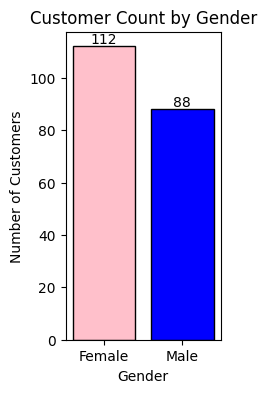

In [7]:
female_count = (customer_df["Gender"] == "Female").sum()
male_count = (customer_df["Gender"] == "Male").sum()

print("# Of Female Customers", female_count)
print("# Of Male Customers", male_count)

# Count male vs female customers
gender_counts = customer_df["Gender"].value_counts()

plt.figure(figsize=(2, 4))
plt.bar(gender_counts.index, gender_counts.values, color=['pink', 'blue'], edgecolor='black')

plt.xlabel('Gender')
plt.ylabel('Number of Customers')
plt.title('Customer Count by Gender')

# Add value labels on top of bars
for i, v in enumerate(gender_counts.values):
    plt.text(i, v + 1, str(v), ha='center', fontsize=10)

plt.show()

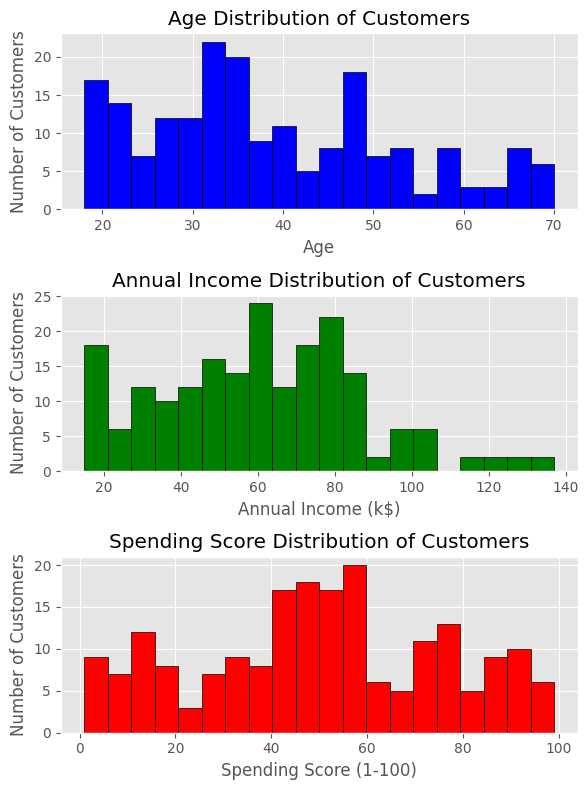

In [8]:
# bar chart of the age range of the customers
# modify so its a 1x3 set of the distribution of age, annual income and spending score
plt.style.use('ggplot')  # Use ggplot style for better aesthetics
plt.figure(figsize=(6, 8))  # Increase height

plt.subplot(3, 1, 1)
plt.hist(customer_df["Age"], bins=20, color='blue', edgecolor='black')
plt.xlabel('Age')
plt.ylabel('Number of Customers')
plt.title('Age Distribution of Customers')

plt.subplot(3, 1, 2)
plt.hist(customer_df["Annual Income (k$)"], bins=20, color='green', edgecolor='black')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Number of Customers')
plt.title('Annual Income Distribution of Customers')

plt.subplot(3, 1, 3)
plt.hist(customer_df["Spending Score (1-100)"], bins=20, color='red', edgecolor='black')
plt.xlabel('Spending Score (1-100)')
plt.ylabel('Number of Customers')
plt.title('Spending Score Distribution of Customers')

plt.tight_layout()
plt.show()


Analyze relationship between Age, Annual Income, and Spending Score

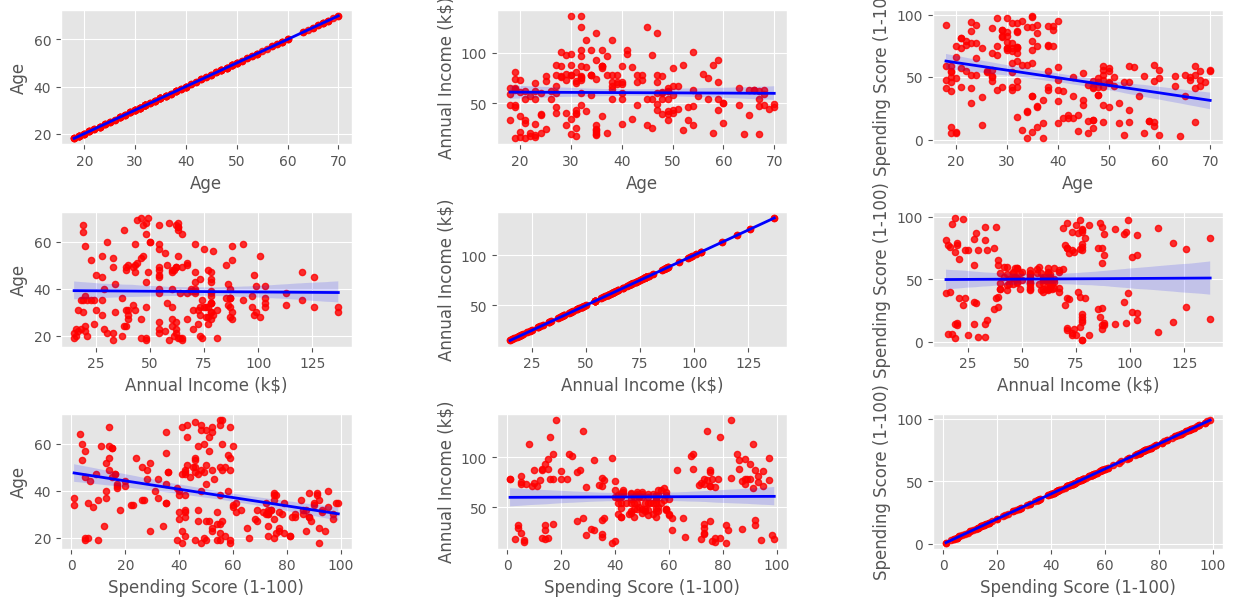

In [9]:
plt.figure(1 , figsize = (15 , 7))
n = 0 

for x in ['Age' , 'Annual Income (k$)' , 'Spending Score (1-100)']:
    for y in ['Age' , 'Annual Income (k$)' , 'Spending Score (1-100)']:
        n += 1
        plt.subplot(3 , 3 , n)
        plt.subplots_adjust(hspace = 0.5 , wspace = 0.5)

        sns.regplot(
            x=x,
            y=y,
            data=customer_df,
            scatter_kws={'s': 20, 'color': 'red'},      # dot size + color
            line_kws={'color': 'blue', 'linewidth': 2} # trend line color + thinness
        )

        plt.ylabel(y)

plt.show()

- **Age vs. Annual Income** - fairly normal distribution. no correlation. many customers between ages 30-35 and mid-late 40s have higher annual incomes.

- **Age vs. Spending Score** - negative correlation between age and spending score. Younger Customers tend to have higher spending scores than older customers. Younger shoppers may be more engaged, impulsive, or responsive to mall offerings

- **Spending Score vs. Annual Income** - There is no correlation between annual income and spending score. many low income earners have just as high ( if not higher) spending scores thatn those with higher incomes. 
 > - Most customers fall into a middle-income, middle-spending group where the annual income is ~40k–70k and the spending score is ~40–60

Plot **Age** vs. **Spending Score** with respect to **gender**

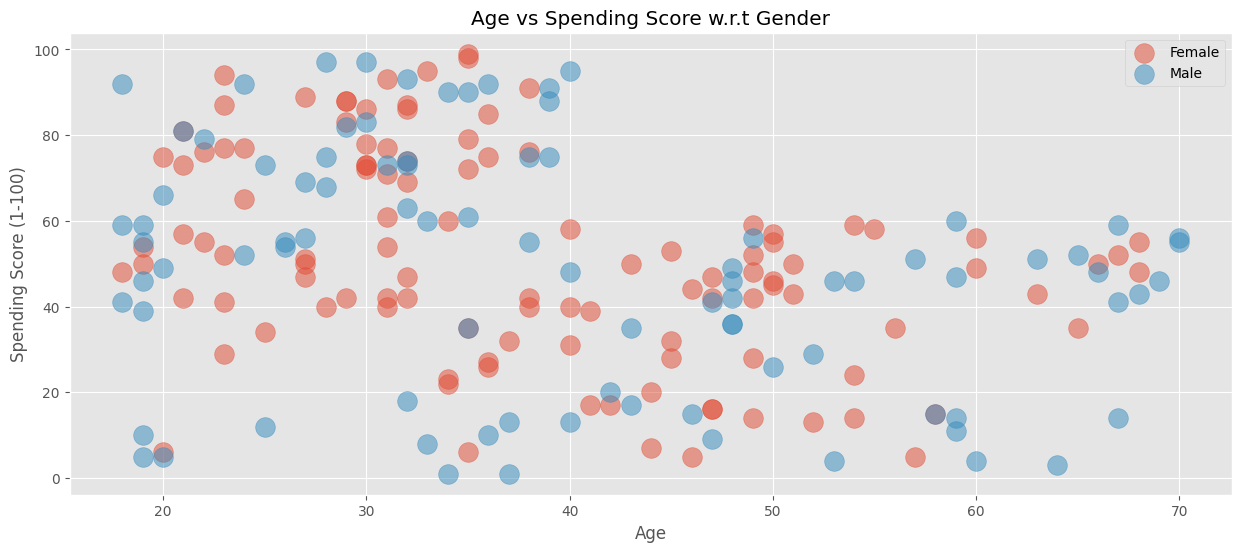

In [10]:
plt.figure(1 , figsize = (15 , 6))
for gender in ['Female' , 'Male']:
    plt.scatter(x = 'Age' , y = 'Spending Score (1-100)' , data = customer_df[customer_df['Gender'] == gender] ,
                s = 200 , alpha = 0.5 , label = gender)
plt.xlabel('Age'), plt.ylabel('Spending Score (1-100)') 
plt.title('Age vs Spending Score w.r.t Gender')
plt.legend()
plt.show()

Plot **Annual Income** vs. **Spending Score** with respect to **gender**

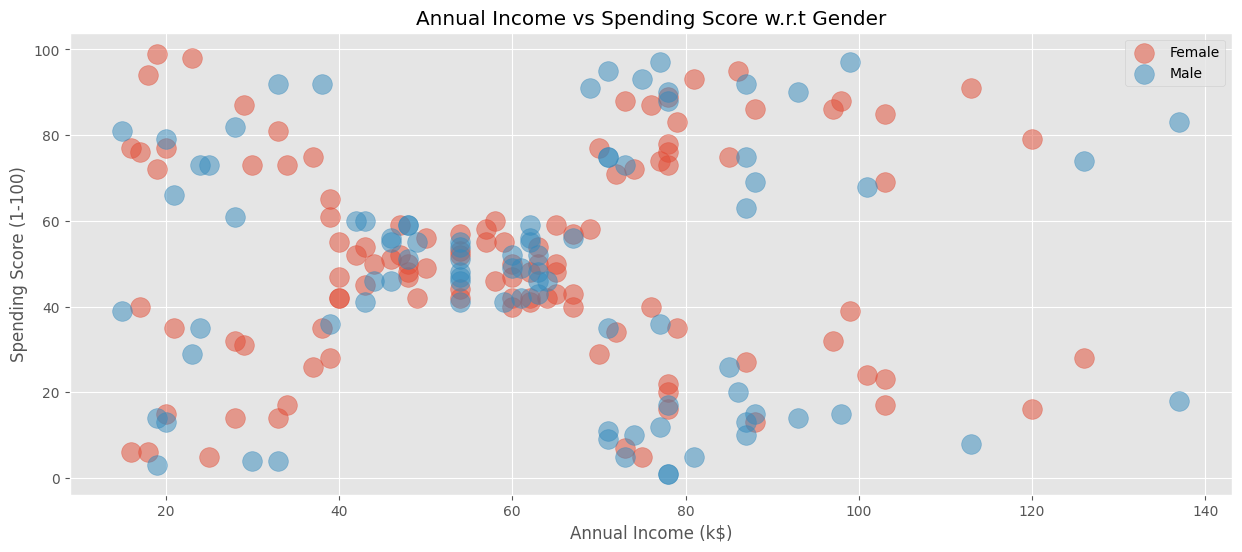

In [11]:
plt.figure(1 , figsize = (15 , 6))
for gender in ['Female' , 'Male']:
    plt.scatter(x = 'Annual Income (k$)' , y = 'Spending Score (1-100)' , data = customer_df[customer_df['Gender'] == gender] ,
                s = 200 , alpha = 0.5 , label = gender)
plt.xlabel('Annual Income (k$)'), plt.ylabel('Spending Score (1-100)') 
plt.title('Annual Income vs Spending Score w.r.t Gender')
plt.legend()
plt.show()

C:\Users\einob\AppData\Local\Temp\ipykernel_38556\1655527063.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[0], data=customer_df, x="Gender", y="Age", palette=["blue", "pink"])
C:\Users\einob\AppData\Local\Temp\ipykernel_38556\1655527063.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[1], data=customer_df, x="Gender", y="Annual Income (k$)", palette=["blue", "pink"])
C:\Users\einob\AppData\Local\Temp\ipykernel_38556\1655527063.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[2], data=customer_df, x="Gende

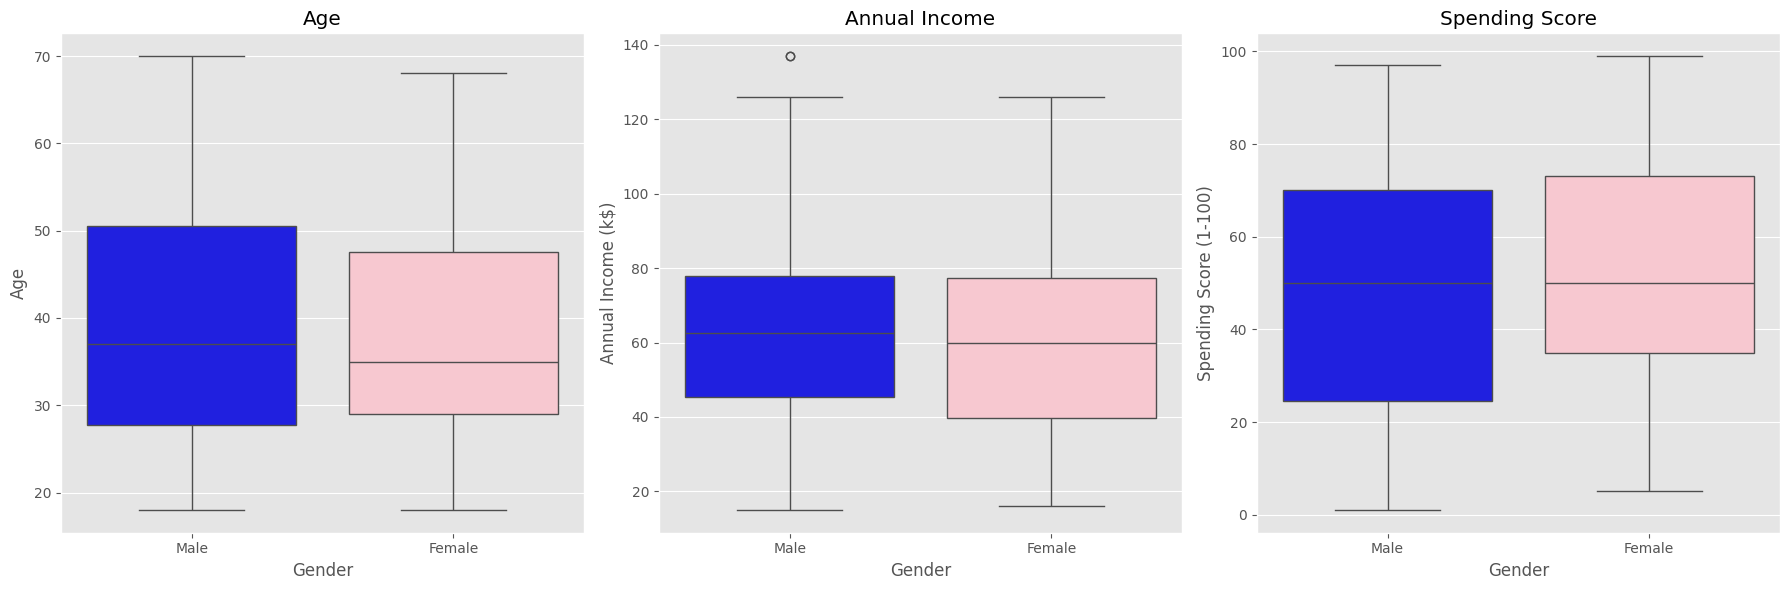

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

sns.boxplot(ax=axes[0], data=customer_df, x="Gender", y="Age", palette=["blue", "pink"])
axes[0].set_title("Age")

sns.boxplot(ax=axes[1], data=customer_df, x="Gender", y="Annual Income (k$)", palette=["blue", "pink"])
axes[1].set_title("Annual Income")

sns.boxplot(ax=axes[2], data=customer_df, x="Gender", y="Spending Score (1-100)", palette=["blue", "pink"])
axes[2].set_title("Spending Score")

plt.tight_layout()
plt.show()


When analysing the gender breakdown between the attributes:
- Men tend to be older than the women customers
- The Female Income Distribution is tighter than men, clustering around the middle-income range. the men have a wider distribution with a high income outlier around 140K.
- Women have a slighltly higher spending score with a tighter distribution than men. This suggests women are outspending men


# Part 2: kMeans Clustering

In [13]:
# copy that will be used for clustering and analysis
df = customer_df.copy()
# copy for comparison and reference to original data
df_original = df.copy()

### Reusable Function that calculates the ideal k clusters and extra stability diagnostics

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples
from typing import Tuple, Dict, Any, Optional

def choose_k_and_plot(
    X: np.ndarray,
    max_k: int = 12,
    n_init: int = 10,
    random_state: int = 0,
    inertia_elbow_rel_threshold: float = 0.12,
    max_k_offset = 3,   # ignore peaks with k > elbow_k + max_k_offset
    figsize: Tuple[int,int] = (14,6),
    verbose: bool = True,
    height_ratios: Optional[Tuple[float,...]] = None,
    dpi: int = 100,
    annotate_offset: Tuple[float,float] = (0.3, 0.12),
    stack_plots: bool = False
) -> Dict[str, Any]:
    """
    Sweep k from 2..max_k, compute inertia and silhouette, plot both,
    and return metrics plus a recommended k.

    Parameters
    ----------
    X : array-like, shape (n_samples, n_features)
    max_k : int
    n_init : int
    random_state : int
    inertia_elbow_rel_threshold : float
    figsize : tuple (width, height)
    verbose : bool
    height_ratios : optional tuple of floats (applies only when rows > 1)
    dpi : int
    annotate_offset : tuple for annotation placement
    stack_plots : if True, stack the two plots vertically (2 rows x 1 col)

    Returns
    -------
    dict with metrics_df, recommended_k, k_candidates, kmeans_recommended,
    per_cluster_silhouette, cluster_sizes
    """
    # Input checks
    if max_k < 2:
        raise ValueError("max_k must be >= 2")
    ks = list(range(2, max_k + 1))
    inertias = []
    silhs = []

    # Compute metrics for each k
    for k in ks:
        km = KMeans(n_clusters=k, n_init=n_init, random_state=random_state)
        labels = km.fit_predict(X)
        inertias.append(km.inertia_)
        silhs.append(silhouette_score(X, labels))

    metrics_df = pd.DataFrame({'k': ks, 'inertia': inertias, 'silhouette': silhs}).set_index('k')

    # Relative inertia improvements
    rel_improvements = []
    prev = None
    for k in ks:
        cur = metrics_df.loc[k, 'inertia']
        if prev is None:
            rel_improvements.append(np.nan)
        else:
            rel_improvements.append((prev - cur) / prev)
        prev = cur
    metrics_df['rel_inertia_improvement'] = rel_improvements

    # Detect elbow (first k where relative improvement falls below threshold)
    elbow_k = None
    for k in ks[1:]:
        if metrics_df.loc[k, 'rel_inertia_improvement'] < inertia_elbow_rel_threshold:
            elbow_k = k - 1
            break
    if elbow_k is None:
        elbow_k = ks[-1]

    # silhouette_k: k with maximum silhouette score
    silhouette_k = int(metrics_df['silhouette'].idxmax())
    sil_max = metrics_df.loc[silhouette_k, 'silhouette']
    sil_elbow = metrics_df.loc[elbow_k, 'silhouette']

    # metrics_df indexed by k, ks is list(range(2, max_k+1))
    sil_series = metrics_df['silhouette'].values  # aligned with ks order
    rel_series = metrics_df['rel_inertia_improvement'].values  # NaN for first entry

    # Recommendation logic:
        # Inertia asks **are the clusters tight**. 
        # The silhouette asks **are they separated**.
    # This chooses a k based on the silhouette peak and inertia elbow
    # if silhouette is much higher than elbow, find the smallest relative silhouette peak and choose that k
    
    # Helper: strict local peak test for silhouette at position i (0-based index into ks)
    def is_local_peak(i, arr):
        # need both neighbors to exist
        if i - 1 < 0 or i + 1 >= len(arr):
            return False
        return (arr[i] > arr[i - 1]) and (arr[i] > arr[i + 1])

    # 1) Find candidate ks where rel_inertia_improvement decreases compared to previous step
    #    (i.e., rel_series[i] < rel_series[i-1]). Start from i=1 because rel_series[0] is NaN.
    decrease_indices = []
    for i in range(1, len(rel_series)):
        prev = rel_series[i - 1]
        cur = rel_series[i]
        # skip if prev is nan (first entry) or cur is nan
        if np.isnan(prev) or np.isnan(cur):
            continue
        if cur < prev:
            decrease_indices.append(i)  # store index into ks/sil_series

    # 2) Scan candidate indices in ascending order and pick the first that is a strict local silhouette peak
    recommended_k = None
    rationale = None
    candidate_peaks = []
    for idx in decrease_indices:
        k_val = ks[idx]  # map index to actual k
        if is_local_peak(idx, sil_series):
            recommended_k = k_val
            rationale = ("first k where rel_inertia_improvement decreases and silhouette is a local peak")
            candidate_peaks.append(k_val)
            break

    # 3) If none of the decrease candidates are local peaks, try a small, controlled fallback:
    if recommended_k is None:
        # Option A: look forward from the first decrease index for the next local silhouette peak
        if len(decrease_indices) > 0:
            start_idx = decrease_indices[0]
            found = False
            for idx in range(start_idx, len(ks)):
                if is_local_peak(idx, sil_series):
                    recommended_k = ks[idx]
                    rationale = ("no decrease-candidate was itself a peak; selected next local silhouette peak "
                                f"after first decrease at k={ks[start_idx]}")
                    found = True
                    break
            if not found:
                # Option B: if still nothing, prefer the elbow candidate (first k where rel improvement falls below threshold)
                # Compute elbow_k as before (first k where rel_inertia_improvement < inertia_elbow_rel_threshold)
                elbow_k = None
                for k in ks[1:]:
                    if metrics_df.loc[k, 'rel_inertia_improvement'] < inertia_elbow_rel_threshold:
                        elbow_k = k - 1
                        break
                if elbow_k is None:
                    elbow_k = ks[-1]
                # If elbow_k is itself a local peak, choose it; otherwise choose the nearest local peak to elbow_k if any
                elbow_idx = ks.index(elbow_k)
                if is_local_peak(elbow_idx, sil_series):
                    recommended_k = elbow_k
                    rationale = "fallback: elbow_k is not a decrease-candidate peak but is itself a local silhouette peak"
                else:
                    # find nearest local peak to elbow (search outward)
                    nearest_peak = None
                    for offset in range(1, max(len(ks), 10)):
                        left = elbow_idx - offset
                        right = elbow_idx + offset
                        if left >= 0 and is_local_peak(left, sil_series):
                            nearest_peak = ks[left]
                            break
                        if right < len(ks) and is_local_peak(right, sil_series):
                            nearest_peak = ks[right]
                            break
                    if nearest_peak is not None:
                        recommended_k = nearest_peak
                        rationale = ("fallback: no decrease-candidate peaks; chose nearest local silhouette peak "
                                    f"to elbow_k (k={nearest_peak})")
                    else:
                        # final fallback: choose the global silhouette peak only if it's not absurdly far from elbow
                        silhouette_k = int(metrics_df['silhouette'].idxmax())
                        sil_max = metrics_df.loc[silhouette_k, 'silhouette']
                        # allow a reasonable offset from elbow (tunable)
                        max_k_offset = 5
                        if abs(silhouette_k - elbow_k) <= max_k_offset:
                            recommended_k = silhouette_k
                            rationale = ("final fallback: chose global silhouette peak because no local peaks found "
                                        f"near elbow and within offset {max_k_offset}")
                        else:
                            recommended_k = elbow_k
                            rationale = ("final fallback: global silhouette peak too far from elbow; chose elbow_k for parsimony")

        else:
            # No decreases found at all (rare). Fall back to silhouette peak or elbow as before.
            silhouette_k = int(metrics_df['silhouette'].idxmax())
            elbow_k = None
            for k in ks[1:]:
                if metrics_df.loc[k, 'rel_inertia_improvement'] < inertia_elbow_rel_threshold:
                    elbow_k = k - 1
                    break
            if elbow_k is None:
                elbow_k = ks[-1]
            # prefer silhouette_k if it's a local peak and reasonably close to elbow_k
            if is_local_peak(ks.index(silhouette_k), sil_series) and abs(silhouette_k - elbow_k) <= 5:
                recommended_k = silhouette_k
                rationale = "no rel_inertia decreases detected; chose local global silhouette peak near elbow"
            else:
                recommended_k = elbow_k
                rationale = "no rel_inertia decreases detected; chose elbow_k for parsimony"

    # Ensure recommended_k is set
    if recommended_k is None:
        # ultimate fallback: global silhouette peak
        recommended_k = int(metrics_df['silhouette'].idxmax())
        rationale = "fallback to global silhouette peak (no other rule matched)"

    # (optional) print debug info when verbose
    if verbose:
        print("decrease_indices (ks):", [ks[i] for i in decrease_indices])
        print("local silhouette peaks:", [ks[i] for i in range(len(ks)) if is_local_peak(i, sil_series)])
        print("chosen recommended_k:", recommended_k)
        print("rationale:", rationale)

    
    km_rec = KMeans(n_clusters=recommended_k, n_init=n_init, random_state=random_state).fit(X)
    labels_rec = km_rec.labels_
    svals = silhouette_samples(X, labels_rec)
    per_cluster_sil = pd.Series(svals).groupby(labels_rec).mean()
    cluster_sizes = np.bincount(labels_rec)

    # Plotting: choose layout
    if stack_plots:
        nrows, ncols = 2, 1
    else:
        nrows, ncols = 1, 2

    # Validate height_ratios: only pass to gridspec_kw when it matches nrows
    gridspec_kw = {}
    if height_ratios is not None:
        if len(height_ratios) == nrows:
            gridspec_kw['height_ratios'] = height_ratios
        else:
            # ignore invalid height_ratios to avoid matplotlib error
            if verbose:
                print(f"Warning: provided height_ratios length {len(height_ratios)} "
                      f"does not match number of rows {nrows}. Ignoring height_ratios.")

    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=figsize,
        dpi=dpi,
        gridspec_kw=gridspec_kw if gridspec_kw else None,
        constrained_layout=True
    )

    # Normalize axes to a 2-element list for consistent indexing
    if nrows == 1 and ncols == 2:
        ax1, ax2 = axes
    elif nrows == 2 and ncols == 1:
        ax1, ax2 = axes[0], axes[1]
    else:
        # fallback: flatten
        ax1, ax2 = np.array(axes).ravel()[:2]

    # Inertia plot (elbow)
    ax1.plot(ks, metrics_df['inertia'], marker='o', color='C0')
    ax1.set_xlabel('Number of clusters k')
    ax1.set_ylabel('Inertia (SSE)')
    ax1.set_title('Elbow Method (Inertia)')
    ax1.grid(alpha=0.25)
    ax1.axvline(recommended_k, color='gray', linestyle='--', alpha=0.6)
    ax1.annotate(
        f"recommended k={recommended_k}",
        xy=(recommended_k, metrics_df.loc[recommended_k, 'inertia']),
        xycoords='data',
        xytext=(
            recommended_k + 0.05 * (ax1.get_xlim()[1] - ax1.get_xlim()[0]),
            metrics_df['inertia'].max() * (1 - annotate_offset[1])
        ),
        textcoords='data',
        ha='left',
        va='top',
        bbox=dict(boxstyle='round,pad=0.3', fc='white', ec='gray', alpha=0.9),
        arrowprops=dict(arrowstyle='->', color='gray', lw=1.0, shrinkA=5, shrinkB=5, connectionstyle='arc3,rad=0'),
        fontsize=9
    )

    # Silhouette plot
    ax2.plot(ks, metrics_df['silhouette'], marker='o', color='C1')
    ax2.set_xlabel('Number of clusters k')
    ax2.set_ylabel('Average silhouette score')
    ax2.set_title('Silhouette Score by k')
    ax2.grid(alpha=0.25)
    ax2.axvline(recommended_k, color='gray', linestyle='--', alpha=0.6)
    ax2.annotate(
        f"recommended k={recommended_k}",
        xy=(recommended_k, metrics_df.loc[recommended_k, 'silhouette']),
        xycoords='data',
        xytext=(
            recommended_k + 0.05 * (ax2.get_xlim()[1] - ax2.get_xlim()[0]),
            metrics_df['silhouette'].min() + annotate_offset[1] * (metrics_df['silhouette'].max() - metrics_df['silhouette'].min())
        ),
        textcoords='data',
        ha='left',
        va='bottom',
        bbox=dict(boxstyle='round,pad=0.3', fc='white', ec='gray', alpha=0.9),
        arrowprops=dict(arrowstyle='->', color='gray', lw=1.0, shrinkA=5, shrinkB=5, connectionstyle='arc3,rad=0'),
        fontsize=9
    )

    plt.show()

    if verbose:
        print(f"Elbow candidate k: {elbow_k}")
        print(f"Silhouette peak k: {silhouette_k} (silhouette={sil_max:.3f})")
        print(f"Recommended k: {recommended_k}  — {rationale}")

    result = {
        'metrics_df': metrics_df.reset_index(),
        'recommended_k': int(recommended_k),
        'k_candidates': {'elbow_k': int(elbow_k), 'silhouette_k': int(silhouette_k)},
        'kmeans_recommended': km_rec,
        'per_cluster_silhouette': per_cluster_sil.round(3),
        'cluster_sizes': cluster_sizes
    }
    return result

def diagnostics(X, k):
    km = KMeans(n_clusters=k, n_init=50, random_state=0).fit(X)
    labels = km.labels_
    sil_avg = silhouette_score(X, labels)
    sil_per = pd.Series(silhouette_samples(X, labels)).groupby(labels).mean()
    sizes = np.bincount(labels)
    return {'k':k, 'silhouette_avg':sil_avg, 'silhouette_per_cluster':sil_per.round(3), 'sizes':sizes, 'kmeans':km}



### First we must decide how many k clusters to use based on the elbow method and the peak silhouette scores

### **6 Clusters** is ideal when segmenting based on **Age**, **Income**, and **Spending Score**
### Rationale:
- #### k = 6 gives the highest silhouette score among the decreasing improving inertia values
- #### When Checking for Stability anything with a k > 6 gives unstable values

decrease_indices (ks): [4, 6, 7, 9]
local silhouette peaks: [6]
chosen recommended_k: 6
rationale: first k where rel_inertia_improvement decreases and silhouette is a local peak


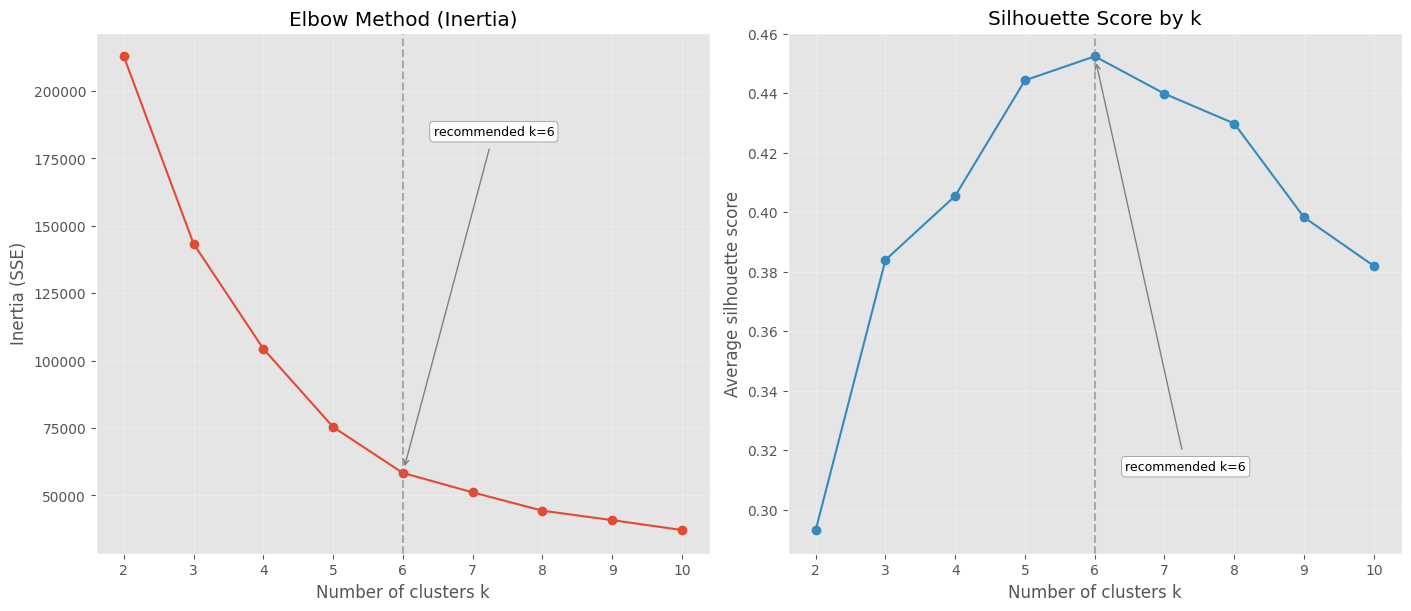

Elbow candidate k: 8
Silhouette peak k: 6 (silhouette=0.452)
Recommended k: 6  — first k where rel_inertia_improvement decreases and silhouette is a local peak
    k        inertia  silhouette  rel_inertia_improvement
0   2  212840.169821    0.293166                      NaN
1   3  143342.751572    0.383935                 0.326524
2   4  104366.151456    0.405463                 0.271912
3   5   75350.779172    0.444286                 0.278015
4   6   58300.443322    0.452344                 0.226279
5   7   51116.986945    0.439789                 0.123214
6   8   44312.468812    0.429776                 0.133117
7   9   40809.751227    0.398267                 0.079046
8  10   37128.008679    0.381935                 0.090217

 Recommended k: 6
Per-cluster silhouette means:
 0    0.442
1    0.410
2    0.584
3    0.392
4    0.502
5    0.424
dtype: float64
Cluster sizes: [45 35 22 38 39 21]


In [15]:
# Select features for clustering
cols = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
X = df[cols].dropna().values   # numpy array (n_samples, n_features)

# If you want to keep the original indices for mapping labels back:
sel = df[cols].dropna()
X = sel.values
sel_index = sel.index

# X is your feature matrix (numpy array)
res = choose_k_and_plot(X, max_k=10, n_init=20, random_state=42)

# Inspect metrics
print(res['metrics_df'])

# Recommended k and diagnostics
print("\n Recommended k:", res['recommended_k'])
print("Per-cluster silhouette means:\n", res['per_cluster_silhouette'])
print("Cluster sizes:", res['cluster_sizes'])


In [16]:
# Check diagnostics to see how avg silhouette values for each k compare
# also chack Adjusted Rand Score to see how stable the chosen k clusters are
# sweep for the selected range of k
results = [diagnostics(X, k) for k in range(4,9)]
for r in results:
    print(r['k'], "avg sil:", round(r['silhouette_avg'],3), "sizes:", r['sizes'])
    # print("per-cluster sil:\n", r['silhouette_per_cluster'], "\n")

# stability check for k=6
for r in results:
    k = int(r['k'])
    km_a = KMeans(n_clusters=k, n_init=50, random_state=0).fit(X)
    km_b = KMeans(n_clusters=k, n_init=50, random_state=42).fit(X)
    print("ARI k=",k, " between seeds:", round(adjusted_rand_score(km_a.labels_, km_b.labels_), 3))

# NOTE:
#   adjusted_rand_score - adjusts for chance when evaluating the similarity between two clusterings of data. 
#   It's a measure used in clustering analysis to assess how well the clusters produced by different methods 
#   or algorithms agree with each other or with a reference clustering
# EXTRA NOTE: 
#   - **Range**: ARI ranges from \(-1\) to \(1\).  
#   - **1** = perfect match.  
#   - **0** ≈ random agreement expected by chance.  
#   - **< 0** = less agreement than expected by chance.  

4 avg sil: 0.405 sizes: [95 38 39 28]
5 avg sil: 0.444 sizes: [23 39 79 23 36]
6 avg sil: 0.452 sizes: [38 35 39 45 21 22]
7 avg sil: 0.44 sizes: [45 35 28 22 21 38 11]
8 avg sil: 0.428 sizes: [37 10 22 44 29 22 10 26]
ARI k= 4  between seeds: 1.0
ARI k= 5  between seeds: 1.0
ARI k= 6  between seeds: 1.0
ARI k= 7  between seeds: 0.981
ARI k= 8  between seeds: 0.987


### **4 Clusters** is ideal when segmenting based on **Age**, and **Spending Score**

### **Rationale:**
- #### the local silhouette peaks: *[4, 8]*  and the decreasing improving inertia values of *[4, 5, 8, 9, 10]* indicate that 4 and 8 are both viable solutions. the line chart shows that k=4 gives a signifcant silhouette peak when compared to k=8
- #### the ARI stability indicates that k > 6 gives less stable clustering

decrease_indices (ks): [4, 5, 8, 9, 10]
local silhouette peaks: [4, 8]
chosen recommended_k: 4
rationale: first k where rel_inertia_improvement decreases and silhouette is a local peak


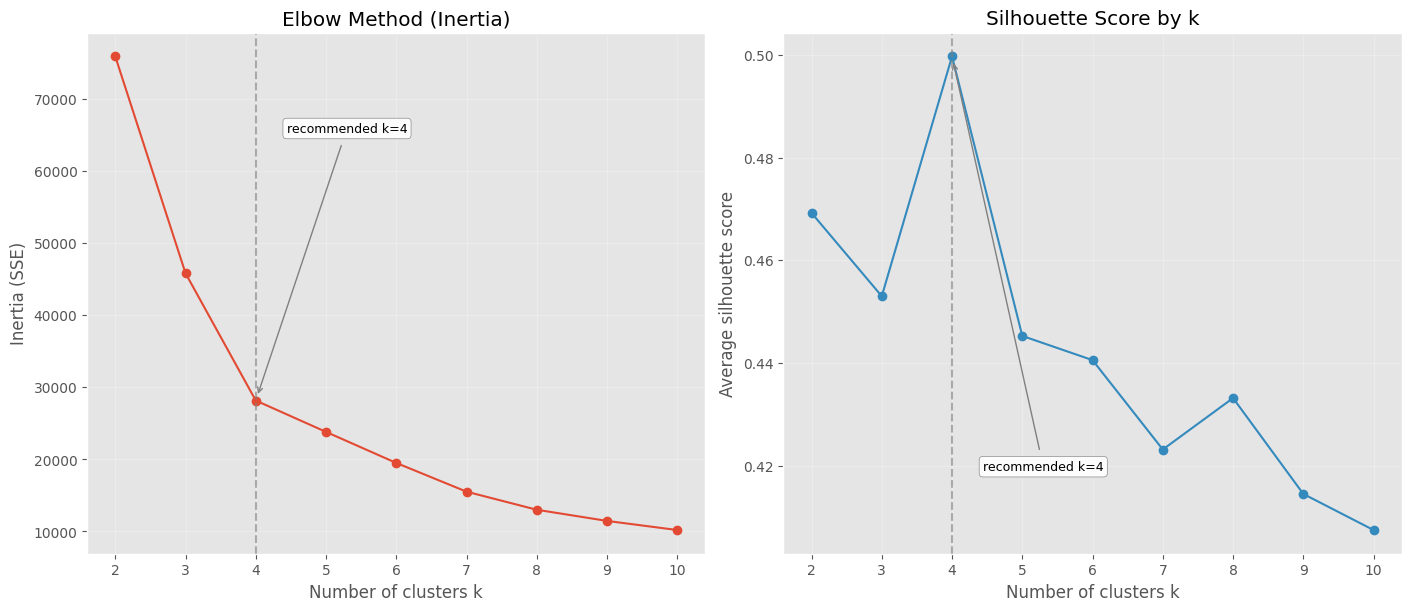

Elbow candidate k: 8
Silhouette peak k: 4 (silhouette=0.500)
Recommended k: 4  — first k where rel_inertia_improvement decreases and silhouette is a local peak
    k       inertia  silhouette  rel_inertia_improvement
0   2  75949.156010    0.469234                      NaN
1   3  45840.676616    0.453001                 0.396429
2   4  28165.583567    0.499739                 0.385577
3   5  23811.523525    0.445267                 0.154588
4   6  19502.407839    0.440548                 0.180968
5   7  15514.193134    0.423135                 0.204499
6   8  13002.466488    0.433161                 0.161899
7   9  11453.288911    0.414477                 0.119145
8  10  10186.501073    0.407443                 0.110605

 Recommended # of k: 4 

Per-cluster silhouette means:
 0    0.509
1    0.596
2    0.454
3    0.420
dtype: float64
Cluster sizes: [48 57 48 47]


In [17]:
# Select features for clustering
cols = ['Age', 'Spending Score (1-100)']
X = df[cols].dropna().values   # numpy array (n_samples, n_features)

# If you want to keep the original indices for mapping labels back:
sel = df[cols].dropna()
X = sel.values
sel_index = sel.index


# X is your feature matrix (numpy array)
res = choose_k_and_plot(X, max_k=10, n_init=20, random_state=42)

# Inspect metrics
print(res['metrics_df'])

# Recommended k and diagnostics
print("\n Recommended # of k:", res['recommended_k'],'\n')
print("Per-cluster silhouette means:\n", res['per_cluster_silhouette'])
print("Cluster sizes:", res['cluster_sizes'])



In [18]:
# Check diagnostics to see how avg silhouette values for each k compare
# also chack Adjusted Rand Score to see how stable the chosen k clusters are
# sweep for the selected range of k
results = [diagnostics(X, k) for k in range(3,10)]
for r in results:
    print(r['k'], "avg sil:", round(r['silhouette_avg'],3), "sizes:", r['sizes'])
    # print("per-cluster sil:\n", r['silhouette_per_cluster'], "\n")

# stability check for k=6
for r in results:
    k = int(r['k'])
    km_a = KMeans(n_clusters=k, n_init=50, random_state=0).fit(X)
    km_b = KMeans(n_clusters=k, n_init=50, random_state=42).fit(X)
    print("ARI k=",k, " between seeds:", round(adjusted_rand_score(km_a.labels_, km_b.labels_), 3))

3 avg sil: 0.453 sizes: [47 91 62]
4 avg sil: 0.5 sizes: [48 57 48 47]
5 avg sil: 0.446 sizes: [57 34 39 40 30]
6 avg sil: 0.438 sizes: [30 39 21 22 57 31]
7 avg sil: 0.423 sizes: [28 36 38 30 18 22 28]
8 avg sil: 0.432 sizes: [22 36 20 23 28 31 27 13]
9 avg sil: 0.418 sizes: [27 32 12 23 25 25 21 15 20]
ARI k= 3  between seeds: 1.0
ARI k= 4  between seeds: 1.0
ARI k= 5  between seeds: 1.0
ARI k= 6  between seeds: 0.974
ARI k= 7  between seeds: 1.0
ARI k= 8  between seeds: 0.971
ARI k= 9  between seeds: 0.955


### **4 k clusters** or **10 k clusters** are ideal when clustering based on **Age** and **Annual Income**

### **Rationale**
- #### When Evaluating on **Age** and **Annual Income** , the following silhouette scores indicate that though k=13 has a higher silhouette score, the k is too high to be useful. 
- #### k = 10 is also a high silhouette score but k is still too large:
- ##### local silhouette peaks: [4, 10]
- ##### 4 avg sil: 0.434 sizes: [73 47 56 24]
- ##### 10 avg sil: 0.42 sizes: [23 10 18 23 21 23  8 18 33 23]
- ##### 11 avg sil: 0.415 sizes: [23 21 18 22  8 13 12 18 20 12 33]
- ##### 13 avg sil: 0.429 sizes: [ 8 18 18 16 23 22  9 18  7  7 13 23 18]

#### When evaluating **inertia** the decrease_indices (ks): **[5, 6, 7, 8, 10, 11]** which doesn't include 4 but its worth trying since it has the highest silhouette value

#### When evaluating model stability, any k > 6 is less stable (ARI < 1). so **k = 4** may be better than **k=10**

decrease_indices (ks): [5, 6, 7, 8, 10, 11]
local silhouette peaks: [4, 10]
chosen recommended_k: 10
rationale: first k where rel_inertia_improvement decreases and silhouette is a local peak


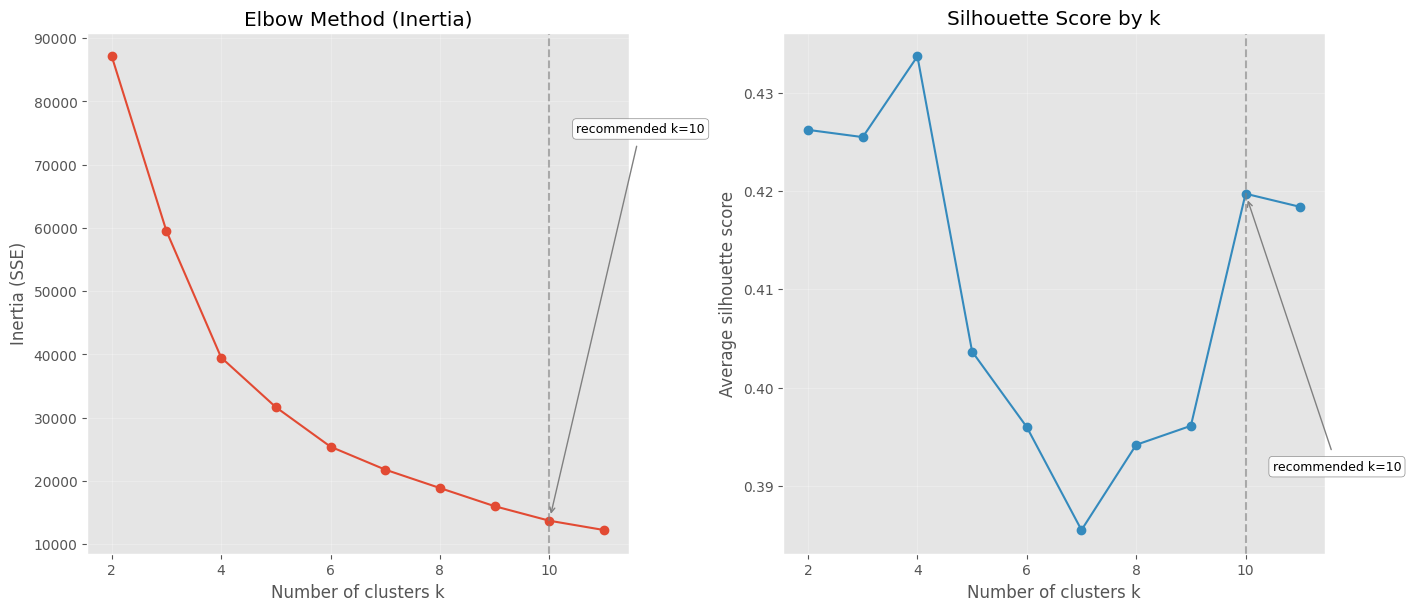

Elbow candidate k: 10
Silhouette peak k: 4 (silhouette=0.434)
Recommended k: 10  — first k where rel_inertia_improvement decreases and silhouette is a local peak
    k       inertia  silhouette  rel_inertia_improvement
0   2  87121.565915    0.426209                      NaN
1   3  59486.961439    0.425473                 0.317196
2   4  39502.778501    0.433686                 0.335942
3   5  31651.380885    0.403666                 0.198756
4   6  25399.022004    0.395981                 0.197538
5   7  21774.976366    0.385511                 0.142684
6   8  18864.876029    0.394180                 0.133644
7   9  15993.235557    0.396110                 0.152222
8  10  13697.901521    0.419716                 0.143519
9  11  12222.056951    0.418376                 0.107742

 Recommended # of k: 10 

Per-cluster silhouette means:
 0    0.503
1    0.367
2    0.371
3    0.504
4    0.443
5    0.372
6    0.424
7    0.445
8    0.438
9    0.325
dtype: float64
Cluster sizes: [ 8 19 23 23 

In [19]:
# Select features for clustering
cols = ['Age', 'Annual Income (k$)']
X = df[cols].dropna().values   # numpy array (n_samples, n_features)

# If you want to keep the original indices for mapping labels back:
sel = df[cols].dropna()
X = sel.values
sel_index = sel.index


# X is your feature matrix (numpy array)
res = choose_k_and_plot(X, max_k=11, n_init=20, random_state=42)

# Inspect metrics
print(res['metrics_df'])

# Recommended k and diagnostics
print("\n Recommended # of k:", res['recommended_k'],'\n')
print("Per-cluster silhouette means:\n", res['per_cluster_silhouette'])
print("Cluster sizes:", res['cluster_sizes'])

In [20]:
# Check diagnostics to see how avg silhouette values for each k compare
# also chack Adjusted Rand Score to see how stable the chosen k clusters are
# sweep for the selected range of k
results = [diagnostics(X, k) for k in range(4,12)]
for r in results:
    print(r['k'], "avg sil:", round(r['silhouette_avg'],3), "sizes:", r['sizes'])
    # print("per-cluster sil:\n", r['silhouette_per_cluster'], "\n")

# stability check for k=6
for r in results:
    k = int(r['k'])
    km_a = KMeans(n_clusters=k, n_init=50, random_state=0).fit(X)
    km_b = KMeans(n_clusters=k, n_init=50, random_state=42).fit(X)
    print("ARI k=",k, " between seeds:", round(adjusted_rand_score(km_a.labels_, km_b.labels_), 3))

# NOTE:
#   adjusted_rand_score - adjusts for chance when evaluating the similarity between two clusterings of data. 
#   It's a measure used in clustering analysis to assess how well the clusters produced by different methods 
#   or algorithms agree with each other or with a reference clustering


4 avg sil: 0.434 sizes: [73 47 56 24]
5 avg sil: 0.404 sizes: [52 42 55 31 20]
6 avg sil: 0.396 sizes: [53 20 39 20 31 37]
7 avg sil: 0.385 sizes: [40 20 40  8 27 28 37]
8 avg sil: 0.394 sizes: [37 36 19  8 25 24 19 32]
9 avg sil: 0.399 sizes: [28 19 25 18 35  8 22 22 23]
10 avg sil: 0.42 sizes: [23 10 18 23 21 23  8 18 33 23]
11 avg sil: 0.415 sizes: [23 21 18 22  8 13 12 18 20 12 33]
ARI k= 4  between seeds: 1.0
ARI k= 5  between seeds: 0.984
ARI k= 6  between seeds: 1.0
ARI k= 7  between seeds: 0.916
ARI k= 8  between seeds: 0.665
ARI k= 9  between seeds: 0.724
ARI k= 10  between seeds: 0.936
ARI k= 11  between seeds: 0.95


### **5 k clusters** is ideal when clustering based on **Annual Income** and **Spending Score**
### **Rationale**
- #### The silhouette peak happens when **k = 5**
- #### The ARI stability decreases when **k > 6**
- #### The Inertia shows that an elbow happens when **k = 5 - 6**
- #### Therefore k = 5 is ideal

decrease_indices (ks): [4, 6, 8, 9, 10]
local silhouette peaks: [5]
chosen recommended_k: 5
rationale: no decrease-candidate was itself a peak; selected next local silhouette peak after first decrease at k=4


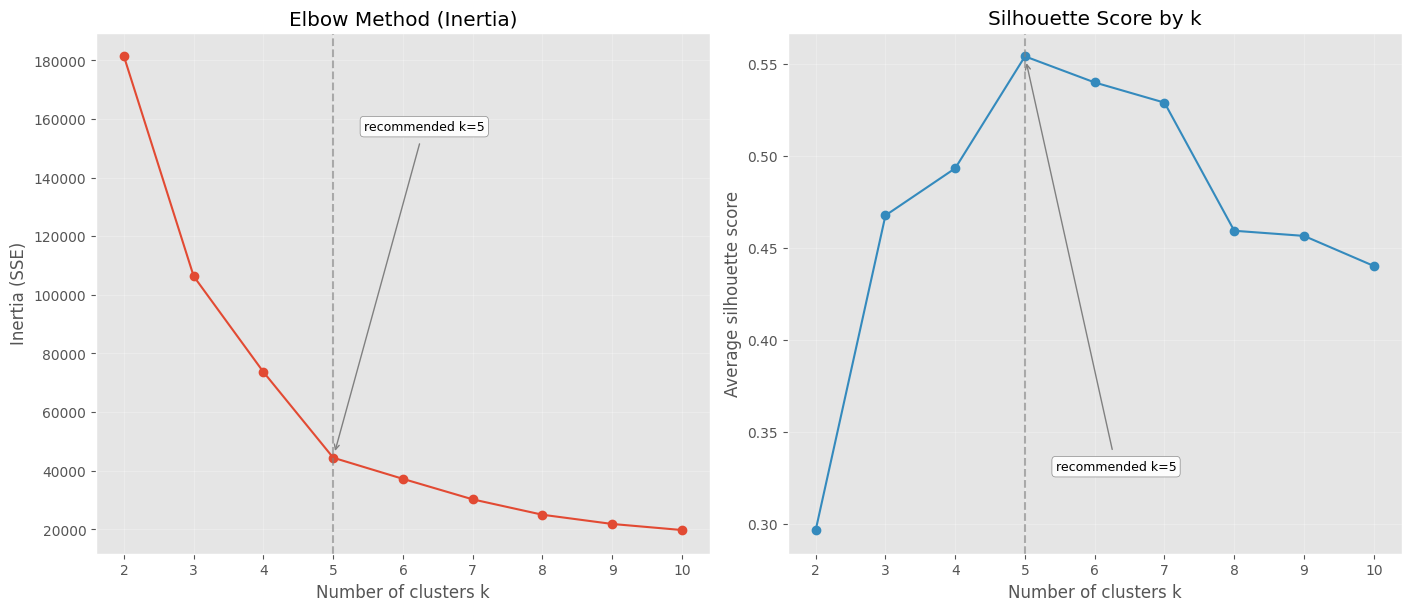

Elbow candidate k: 9
Silhouette peak k: 5 (silhouette=0.554)
Recommended k: 5  — no decrease-candidate was itself a peak; selected next local silhouette peak after first decrease at k=4
    k        inertia  silhouette  rel_inertia_improvement
0   2  181363.595960    0.296897                      NaN
1   3  106348.373062    0.467614                 0.413618
2   4   73679.789039    0.493196                 0.307185
3   5   44448.455448    0.553932                 0.396735
4   6   37233.814511    0.539761                 0.162315
5   7   30241.343618    0.528810                 0.187799
6   8   24995.969781    0.459296                 0.173450
7   9   21850.165283    0.456508                 0.125852
8  10   19779.014121    0.440206                 0.094789

 Recommended # of k: 5 

Per-cluster silhouette means:
 0    0.597
1    0.509
2    0.599
3    0.504
4    0.512
dtype: float64
Cluster sizes: [81 39 22 35 23]
3 avg sil: 0.468 sizes: [123  39  38]
4 avg sil: 0.493 sizes: [100  39  38 

In [21]:
# Select features for clustering
cols = ['Spending Score (1-100)', 'Annual Income (k$)']
X = df[cols].dropna().values   # numpy array (n_samples, n_features)

# If you want to keep the original indices for mapping labels back:
sel = df[cols].dropna()
X = sel.values
sel_index = sel.index

# X is your feature matrix (numpy array)
res = choose_k_and_plot(X, max_k=10, n_init=20, random_state=42)

# Inspect metrics
print(res['metrics_df'])

# Recommended k and diagnostics
print("\n Recommended # of k:", res['recommended_k'],'\n')
print("Per-cluster silhouette means:\n", res['per_cluster_silhouette'])
print("Cluster sizes:", res['cluster_sizes'])


# Check diagnostics to see how avg silhouette values for each k compare
# also chack Adjusted Rand Score to see how stable the chosen k clusters are
# sweep for the selected range of k
results = [diagnostics(X, k) for k in range(3,11)]
for r in results:
    print(r['k'], "avg sil:", round(r['silhouette_avg'],3), "sizes:", r['sizes'])
    # print("per-cluster sil:\n", r['silhouette_per_cluster'], "\n")

# stability check for k=6
for r in results:
    k = int(r['k'])
    km_a = KMeans(n_clusters=k, n_init=50, random_state=0).fit(X)
    km_b = KMeans(n_clusters=k, n_init=50, random_state=42).fit(X)
    print("ARI k=",k, " between seeds:", round(adjusted_rand_score(km_a.labels_, km_b.labels_), 3))


## **Conclusion**
- ### **6 Clusters** is ideal when segmenting based on **Age**, **Income**, and **Spending Score** 
- ### **4 OR 10 k clusters** is ideal when clustering based on **Age** and **Annual Income**
- ### **4 k clusters** is ideal when clustering based on **Age** and **Spending Score**
- ### **5 k clusters** is ideal when clustering based on **Annual Income** and **Spending Score**



# Final KMeans visualizations for each segmentation

## **Age** vs **Spending Score** (k = 4)

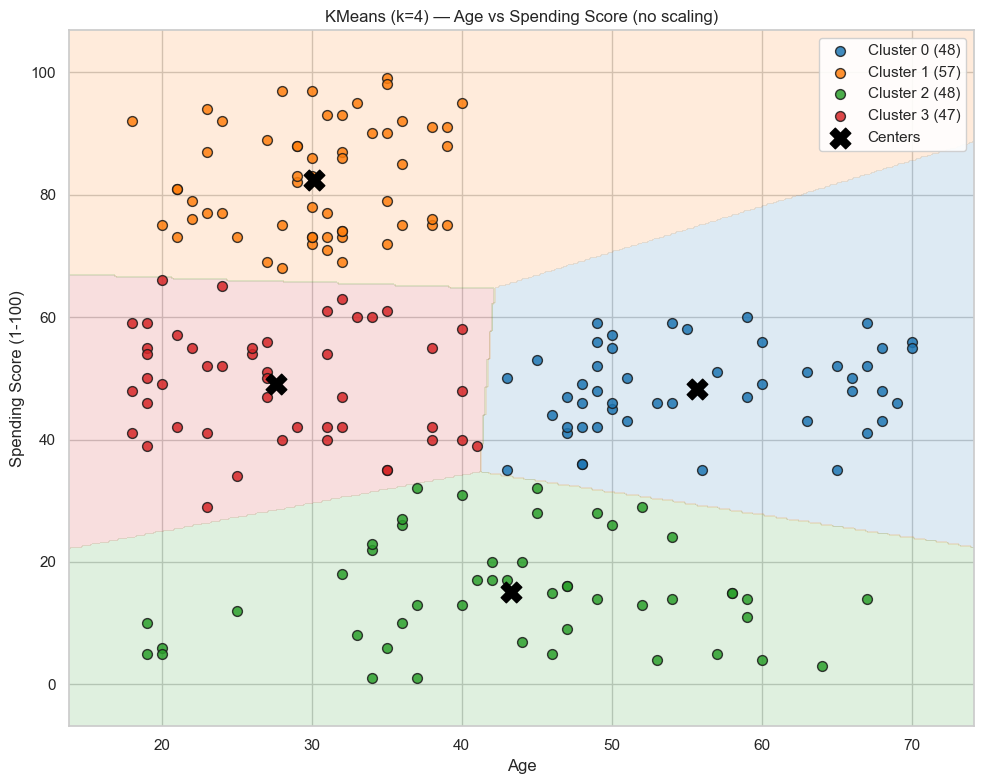

Cluster sizes:
0    48
1    57
2    48
3    47
Name: count, dtype: int64

Cluster share of customers (%):
0    24.0
1    28.5
2    24.0
3    23.5
Name: count, dtype: float64

Cluster centers (original feature scale):


,Age,Spending Score (1-100),Cluster
0,55.708333,48.229167,0
1,30.175439,82.350877,1
2,43.291667,15.020833,2
3,27.617021,49.148936,3



Cluster means (Age, Spending Score):


,Age,Spending Score (1-100)
Cluster,,
0,55.71,48.23
1,30.18,82.35
2,43.29,15.02
3,27.62,49.15


In [22]:
# KMeans visualization: Age vs Spending Score

sns.set(style="whitegrid", context="notebook")

# --- Inputs (use your variables) ---
chosen_k = 4
x_feat = "Age"
y_feat = "Spending Score (1-100)"
df_plot = df[[x_feat, y_feat]].dropna().reset_index(drop=True)  # df assumed to exist

# chosen_k = 5
# features = ['Age', 'Spending Score (1-100)']
# df_plot = df[features]

# --- Fit KMeans on raw 2D data ---
X = df_plot.values
km = KMeans(n_clusters=chosen_k, random_state=42, n_init=50)
labels = km.fit_predict(X)
df_plot["Cluster"] = labels

# --- Create meshgrid in original feature space for decision regions ---
pad_x = (X[:,0].max() - X[:,0].min()) * 0.08
pad_y = (X[:,1].max() - X[:,1].min()) * 0.08
x_min, x_max = X[:,0].min() - pad_x, X[:,0].max() + pad_x
y_min, y_max = X[:,1].min() - pad_y, X[:,1].max() + pad_y

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 400),
    np.linspace(y_min, y_max, 400)
)
grid = np.c_[xx.ravel(), yy.ravel()]
grid_labels = km.predict(grid).reshape(xx.shape)

# --- Plotting ---
plt.figure(figsize=(10, 8))
palette = sns.color_palette("tab10", chosen_k)

# decision regions
plt.contourf(xx, yy, grid_labels, alpha=0.15, levels=np.arange(-0.5, chosen_k+0.5, 1), colors=palette)

# scatter points by cluster
for i in range(chosen_k):
    mask = labels == i
    plt.scatter(X[mask, 0], X[mask, 1],
                s=50, color=palette[i], edgecolor='k', alpha=0.85, label=f"Cluster {i} ({mask.sum()})")

# cluster centers (already in original feature space)
centers = km.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], marker='X', s=220, color='black', label='Centers')

plt.xlabel(x_feat)
plt.ylabel(y_feat)
plt.title(f"KMeans (k={chosen_k}) — Age vs Spending Score (no scaling)")
plt.legend(loc='best', framealpha=0.9)
plt.tight_layout()
plt.show()

# --- Numeric summaries ---
print("Cluster sizes:")
print(pd.Series(labels).value_counts().sort_index())

print("\nCluster share of customers (%):")
print((pd.Series(labels).value_counts().sort_index() / len(df_plot) * 100).round(1))

centers_df = pd.DataFrame(centers, columns=[x_feat, y_feat])
centers_df['Cluster'] = centers_df.index
print("\nCluster centers (original feature scale):")
display(centers_df)

print("\nCluster means (Age, Spending Score):")
display(df_plot.groupby("Cluster")[[x_feat, y_feat]].mean().round(2))


## Cluster Summaries
- **Cluster counts** are roughly even: *48, 57, 48, 47* — no tiny or huge clusters, so KMeans didn’t produce a dominant single group or many tiny outliers.

| **Cluster** | **Centroid (Age, Spending Score)** | **Share (%)** | **Customer persona** |
| --- | --- | --- | --- |
| **0** | **55.71, 48.23** | **24.0** | **Older, moderate spenders.** Established customers with higher age who spend at a steady, mid level; prioritize convenience, trust, and value. Good targets for retention and cross‑sell. |
| **1*** | **30.18, 82.35** | **28.5** | **Young, high spenders (high‑value).** Younger customers with very high engagement and spending; ideal for premium offers, loyalty tiers, and personalized upsells. |
| **2** | **43.29, 15.02** | **24.0** | **Middle‑aged, low spenders.** Lower engagement and low spending despite moderate age; likely price‑sensitive or mismatched on product fit. Test reactivation and product/price experiments. |
| **3** | **27.62, 49.15** | **23.5** | **Young, moderate spenders.** Younger than cluster 0, moderate engagement—good candidates for nudges, social proof, and promotions to move them toward higher spend. |

## Business Priorities 
| **Priority — Cluster** | **Why** | **Actions** |
| --- | --- | --- |
| **Top priority — Cluster 1 (Age ≈ 30, Spending ≈ 82)** | Young, high spend; largest single cluster and immediate revenue driver. | Premium offers; loyalty tiers; early access; personalized high‑margin upsells; VIP communications. |
| **High upside — Cluster 3 (Age ≈ 28, Spending ≈ 49)** | Young, moderate spend — receptive and likely to be nudged to higher spend. | Targeted promotions; personalized recommendations; social proof and referral incentives; A/B test nudges to increase AOV. |
| **Scale gains — Cluster 0 (Age ≈ 56, Spending ≈ 48)** | Older, moderate spend — stable, reliable customer base where small lifts scale. | Retention programs; convenience/value messaging; cross‑sell and bundling; lifecycle email campaigns. |
| **Reactivation / Low priority — Cluster 2 (Age ≈ 43, Spending ≈ 15)** | Middle‑aged, very low spend — low current ROI; may be disengaged or price‑sensitive. | Low‑cost reactivation tests (discounts, targeted surveys); product fit investigation; if response is weak, deprioritize expensive acquisition. |

### Conclusion:

#### When considering Age and Spending Score, **Prioritize Young, Frequent Spenders**

## **Spending Score** vs **Annual Income** (k = 5)

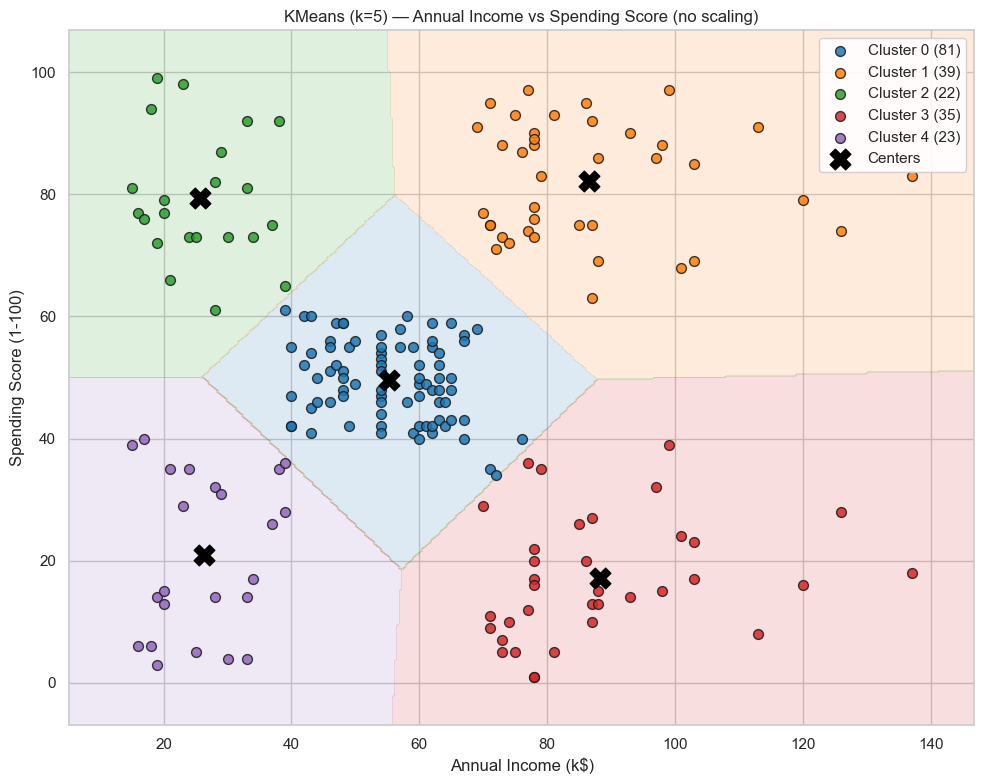

Cluster sizes:
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64

Cluster share of customers (%):
0    40.5
1    19.5
2    11.0
3    17.5
4    11.5
Name: count, dtype: float64

Cluster centers (original feature scale):


,Annual Income (k$),Spending Score (1-100),Cluster
0,55.296296,49.518519,0
1,86.538462,82.128205,1
2,25.727273,79.363636,2
3,88.200000,17.114286,3
4,26.304348,20.913043,4



Cluster means (Annual Income, Spending Score):


,Annual Income (k$),Spending Score (1-100)
Cluster,,
0,55.30,49.52
1,86.54,82.13
2,25.73,79.36
3,88.20,17.11
4,26.30,20.91


In [23]:
# KMeans visualization: Spending Score vs Annual Income

sns.set(style="whitegrid", context="notebook")

# --- Inputs (use your variables) ---
chosen_k = 5
x_feat = "Annual Income (k$)"
y_feat = "Spending Score (1-100)"
df_plot = df[[x_feat, y_feat]].dropna().reset_index(drop=True)  # df assumed to exist


# --- Fit KMeans on raw 2D data ---
X = df_plot.values
km = KMeans(n_clusters=chosen_k, random_state=42, n_init=50)
labels = km.fit_predict(X)
df_plot["Cluster"] = labels

# --- Create meshgrid in original feature space for decision regions ---
pad_x = (X[:,0].max() - X[:,0].min()) * 0.08
pad_y = (X[:,1].max() - X[:,1].min()) * 0.08
x_min, x_max = X[:,0].min() - pad_x, X[:,0].max() + pad_x
y_min, y_max = X[:,1].min() - pad_y, X[:,1].max() + pad_y

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 400),
    np.linspace(y_min, y_max, 400)
)
grid = np.c_[xx.ravel(), yy.ravel()]
grid_labels = km.predict(grid).reshape(xx.shape)

# --- Plotting ---
plt.figure(figsize=(10, 8))
palette = sns.color_palette("tab10", chosen_k)

# decision regions
plt.contourf(xx, yy, grid_labels, alpha=0.15, levels=np.arange(-0.5, chosen_k+0.5, 1), colors=palette)

# scatter points by cluster
for i in range(chosen_k):
    mask = labels == i
    plt.scatter(X[mask, 0], X[mask, 1],
                s=50, color=palette[i], edgecolor='k', alpha=0.85, label=f"Cluster {i} ({mask.sum()})")

# cluster centers (already in original feature space)
centers = km.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], marker='X', s=220, color='black', label='Centers')

plt.xlabel(x_feat)
plt.ylabel(y_feat)
plt.title(f"KMeans (k={chosen_k}) — Annual Income vs Spending Score (no scaling)")
plt.legend(loc='best', framealpha=0.9)
plt.tight_layout()
plt.show()

# --- Numeric summaries ---
print("Cluster sizes:")
print(pd.Series(labels).value_counts().sort_index())

print("\nCluster share of customers (%):")
print((pd.Series(labels).value_counts().sort_index() / len(df_plot) * 100).round(1))

centers_df = pd.DataFrame(centers, columns=[x_feat, y_feat])
centers_df['Cluster'] = centers_df.index
print("\nCluster centers (original feature scale):")
display(centers_df)

print("\nCluster means (Annual Income, Spending Score):")
display(df_plot.groupby("Cluster")[[x_feat, y_feat]].mean().round(2))


## Cluster Summaries

| **Cluster** | **Centroid (Annual Income k$, Spending Score)** | **Share (%)** | **Customer persona** |
| --- | --- | --- | --- |
| **0** | **55.30k, 49.52** | **40.5** | **Mid‑income steady spenders.** Core volume customers who provide predictable revenue; respond to convenience and value. |
| **1*** | **86.54k, 82.13** | **19.5** | **Affluent high spenders.** Premium buyers who value exclusivity and new experiences; top revenue contributors. |
| **2** | **25.73k, 79.36** | **11.0** | **Low‑income, high engagement.** Trend‑driven and loyal despite limited means; high LTV potential if nurtured. |
| **3** | **88.20k, 17.11** | **17.5** | **Wealthy but disengaged.** Have capacity to spend but currently inactive; high upside for reactivation. |
| **4** | **26.30k, 20.91** | **11.5** | **Low‑income, low spenders.** Price‑sensitive and low priority for expensive acquisition; suitable for low‑cost retention. |

## Business Priorities
| **Priority — Cluster** | **Why** | **Actions** |
| --- | --- | --- |
| **Top priority — Cluster 1 (Income 86.54k, Spend 82.13)** | High income and very high spending; strong revenue drivers. | Premium offers; loyalty tiers; personalized high‑margin upsells; VIP events. |
| **High upside — Cluster 2 (Income 25.73k, Spend 79.36)** | Low income but high engagement; trend‑driven and loyal. | Affordable bundles; subscription nudges; social campaigns; referral incentives. |
| **Reactivation opportunity — Cluster 3 (Income 88.20k, Spend 17.11)** | Very high income but very low current spend. | Investigate channel/product fit; targeted concierge outreach; premium experience trials. |
| **Scale gains — Cluster 0 (Income 55.30k, Spend 49.52)** | Largest segment by share; mid income and mid spend where small lifts scale. | Retention programs; cross‑sell and bundling; lifecycle email campaigns; A/B tests. |
| **Low priority — Cluster 4 (Income 26.30k, Spend 20.91)** | Low income and low spend; low ROI for costly acquisition. | Low‑cost retention (email drip); awareness campaigns only if cost‑effective. |

### Conclusion:

#### When considering Annual Income and Spending Score, **Prioritize High Income, Frequent Spenders**

### **Age** vs **Annual Income** vs **Spending Score** (k = 6)
#### 3D Output File: kMeans 3D Output.html

In [29]:
# KMeans visualization: Age vs Annual Income vs Spending Score
%matplotlib inline
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.express as px
import plotly.io as pio
from sklearn.cluster import KMeans
from pathlib import Path

# Optional: choose renderer that works in your environment
# pio.renderers.default = "notebook_connected"   # classic notebook
# pio.renderers.default = "iframe_connected"    # fallback
pio.renderers.default = "browser"               # opens in browser; change if you prefer inline

# --- Prepare data (same order as your X3) ---
X3 = df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']].values

# --- Fit KMeans (your parameters) ---
algorithm = KMeans(
    n_clusters=6,
    init='k-means++',
    n_init=10,
    max_iter=300,
    tol=0.0001,
    random_state=111,
    algorithm='elkan'
)
algorithm.fit(X3)

# Attach labels and centroids
df['label3'] = algorithm.labels_
centroids3 = algorithm.cluster_centers_   # columns: [Age, Annual Income, Spending Score]

# --- Scatter points: one trace per cluster for clean legend/colors ---
palette = px.colors.qualitative.Safe
data = []
unique_labels = sorted(df['label3'].unique())

for i, lab in enumerate(unique_labels):
    mask = df['label3'] == lab
    pts = df.loc[mask, ['Age', 'Spending Score (1-100)', 'Annual Income (k$)']]
    data.append(
        go.Scatter3d(
            x=pts['Age'],
            y=pts['Spending Score (1-100)'],
            z=pts['Annual Income (k$)'],
            mode='markers',
            name=f'Cluster {lab} ({mask.sum()})',
            marker=dict(
                size=5,
                color=palette[i % len(palette)],
                opacity=0.8,
                line=dict(width=0.3, color='black')
            ),
            hovertemplate=(
                f"Cluster: {lab}<br>Age: %{{x}}<br>Spending Score: %{{y}}<br>Annual Income: %{{z}}<extra></extra>"
            )
        )
    )

# --- Centroid trace with labels ---
centroid_text = [f"Centroid {int(i)}" for i in range(len(centroids3))]

data.append(
    go.Scatter3d(
        x=centroids3[:, 0],            # Age
        y=centroids3[:, 2],            # Spending Score
        z=centroids3[:, 1],            # Annual Income
        mode='markers+text',
        name='Centroids',
        marker=dict(size=12, color='black', symbol='diamond', line=dict(color='white', width=1)),
        text=centroid_text,
        textposition='top center',
        hovertemplate="Centroid: %{text}<br>Age: %{x}<br>Spending: %{y}<br>Income: %{z}<extra></extra>"
    )
)

# --- Layout and figure ---
layout = go.Layout(
    title='3D Clusters Age vs Spending Score vs Annual Income',
    margin=dict(l=0, r=0, b=0, t=40),
    scene=dict(
        xaxis=dict(title='Age'),
        yaxis=dict(title='Spending Score (1-100)'),
        zaxis=dict(title='Annual Income (k$)')
    ),
    legend=dict(itemsizing='constant')
)

fig = go.Figure(data=data, layout=layout)
fig.show()


# ---------------------------------------------------------
# Save the interactive figure as an HTML file
# ---------------------------------------------------------

# For a Jupyter notebook, use the notebook's working directory.
# For a Python script, use the folder containing the script.
try:
    output_folder = Path(__file__).resolve().parent
except NameError:
    output_folder = Path.cwd()

output_file = output_folder / "fig_gender.html"

pio.write_html(
    fig=fig,
    file=str(output_file),
    full_html=True,
    include_plotlyjs=True,
    auto_open=False,
    config={
        "responsive": True,
        "displaylogo": False,
        "scrollZoom": True,
    },
)

# --- Numeric summaries ---
print("Cluster sizes:")
sizes = df['label3'].value_counts().sort_index()
print(sizes)

print("\nCluster share of customers (%):")
print((sizes / len(df) * 100).round(1))

features = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
centers_df = pd.DataFrame(centroids3, columns=features)
centers_df['Cluster'] = centers_df.index
centers_df = centers_df[['Cluster'] + features].round(2)

print("\nCluster centers (original feature scale):")
display(centers_df)

Cluster sizes:
label3
0    35
1    45
2    39
3    38
4    21
5    22
Name: count, dtype: int64

Cluster share of customers (%):
label3
0    17.5
1    22.5
2    19.5
3    19.0
4    10.5
5    11.0
Name: count, dtype: float64

Cluster centers (original feature scale):


,Cluster,Age,Annual Income (k$),Spending Score (1-100)
0,0,41.69,88.23,17.29
1,1,56.16,53.38,49.09
2,2,32.69,86.54,82.13
3,3,27.00,56.66,49.13
4,4,44.14,25.14,19.52
5,5,25.27,25.73,79.36


### Now lets cluster based on gender (M/F) for **Age** vs **Annual Income** vs **Spending Score** (k = 6)
#### 3D Output File: kMeans By Gender 3D Output.html

In [27]:
from pathlib import Path
import plotly.io as pio
# encode gender (binary) and include it as a feature
df['Gender'] = df['Gender'].astype('category')
gender_map = {cat: i for i, cat in enumerate(df['Gender'].cat.categories)}
df['Pct_Male'] = df['Gender'].map(gender_map)

# keep only rows with no missing values in the features we will use
feature_cols_with_gender = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)', 'Pct_Male']
df2 = df.dropna(subset=feature_cols_with_gender).copy()

# prepare X3 (no scaling)
X3 = df2[feature_cols_with_gender].values

# fit KMeans (overall model that includes gender)
from sklearn.cluster import KMeans
km_all = KMeans(
    n_clusters=6,
    init='k-means++',
    n_init=10,
    max_iter=300,
    tol=0.0001,
    random_state=111,
    algorithm='elkan'
)
km_all.fit(X3)

# attach labels back to df2 and then to original df (allow NaNs)
import numpy as np
df2['label3'] = km_all.labels_.astype(int)
df['label3'] = np.nan
df.loc[df2.index, 'label3'] = df2['label3'].astype(int)

# cluster gender mix
cluster_gender_mix = pd.crosstab(df2['label3'], df2['Gender'], normalize='index').round(3)
print("Cluster gender mix (by cluster, normalized):")
print(cluster_gender_mix)

# overall cluster centers (no scaler used)
centroids_orig = km_all.cluster_centers_
features = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)', 'Pct_Male']
centers_df = pd.DataFrame(centroids_orig, columns=features)
centers_df['Cluster'] = centers_df.index
centers_df = centers_df[['Cluster', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)', 'Pct_Male']].round(2)

# -------------------------
# Per-gender clustering (separate KMeans for each gender) and 3D plotting
# No label_g columns are written to df or used anywhere
# -------------------------
genders = df['Gender'].dropna().unique()
fig_data = []
palette = px.colors.qualitative.Safe
symbol_map = ['circle', 'diamond', 'cross', 'x', 'triangle-up', 'square']

per_gender_centers = []
per_gender_sizes = []

for gi, g in enumerate(genders):
    sub = df[df['Gender'] == g].dropna(subset=['Age', 'Annual Income (k$)', 'Spending Score (1-100)']).copy()
    if len(sub) == 0:
        continue

    Xg = sub[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']].values
    km = KMeans(n_clusters=6, random_state=111, n_init=10).fit(Xg)
    labels_local = km.labels_  # local only

    # add scatter traces using local labels (do not store them in df)
    for lab in sorted(np.unique(labels_local)):
        mask_idx = np.where(labels_local == lab)[0]
        pts = sub.iloc[mask_idx]
        fig_data.append(go.Scatter3d(
            x=pts['Age'],
            y=pts['Spending Score (1-100)'],
            z=pts['Annual Income (k$)'],
            mode='markers',
            name=f'{g} cluster {lab} ({len(pts)})',
            marker=dict(
                symbol=symbol_map[gi % len(symbol_map)],
                size=5,
                color=palette[int(lab) % len(palette)],
                opacity=0.8,
                line=dict(width=0.3, color='black')
            ),
            hovertemplate=(
                f"Gender: {g}<br>Cluster: {lab}<br>Age: %{{x}}<br>Spending Score: %{{y}}<br>Annual Income: %{{z}}<extra></extra>"
            )
        ))

    # add centroids for this gender (on original scale)
    cent = km.cluster_centers_
    fig_data.append(go.Scatter3d(
        x=cent[:, 0],
        y=cent[:, 2],
        z=cent[:, 1],
        mode='markers+text',
        text=[f'{g} C{int(i)}' for i in range(len(cent))],
        textposition='top center',
        marker=dict(size=9, symbol='diamond', color='black'),
        name=f'{g} centroids'
    ))

    # collect per-gender summaries (local only)
    cent_df = pd.DataFrame(cent, columns=['Age', 'Annual Income (k$)', 'Spending Score (1-100)'])
    cent_df['Gender'] = g
    cent_df['cluster_index'] = cent_df.index
    per_gender_centers.append(cent_df)

    unique, counts = np.unique(labels_local, return_counts=True)
    sizes_df = pd.DataFrame({'cluster_index': unique, 'count': counts})
    sizes_df['Gender'] = g
    per_gender_sizes.append(sizes_df)

# concat per-gender summaries
per_gender_centers_df = pd.concat(per_gender_centers, ignore_index=True).round(3) if per_gender_centers else pd.DataFrame()
per_gender_sizes_df = pd.concat(per_gender_sizes, ignore_index=True) if per_gender_sizes else pd.DataFrame()

# build layout and show the per-gender figure in browser
layout_gender = go.Layout(
    title='Per-gender 3D Clusters: Age vs Spending Score vs Annual Income',
    margin=dict(l=0, r=0, b=0, t=40),
    scene=dict(
        xaxis=dict(title='Age'),
        yaxis=dict(title='Spending Score (1-100)'),
        zaxis=dict(title='Annual Income (k$)')
    ),
    legend=dict(itemsizing='constant')
)

# fig_gender = go.Figure(data=fig_data, layout=layout_gender)
# fig_gender.show()

fig_gender = go.Figure(
    data=fig_data,
    layout=layout_gender
)

# ---------------------------------------------------------
# Save the interactive figure as an HTML file
# ---------------------------------------------------------

# For a Jupyter notebook, use the notebook's working directory.
# For a Python script, use the folder containing the script.
try:
    output_folder = Path(__file__).resolve().parent
except NameError:
    output_folder = Path.cwd()

output_file = output_folder / "fig_gender.html"

pio.write_html(
    fig=fig_gender,
    file=str(output_file),
    full_html=True,
    include_plotlyjs=True,
    auto_open=False,
    config={
        "responsive": True,
        "displaylogo": False,
        "scrollZoom": True,
    },
)

# Show the chart in the notebook.
fig_gender.show()

print(f"Interactive chart saved to: {output_file}")

# --- Display results separately in notebook ---
print("Overall cluster centers (includes Pct_Male):")
display(centers_df)

print("Per-gender cluster centers:")
display(per_gender_centers_df)

print("Per-gender cluster sizes:")
display(per_gender_sizes_df)


# Pairing Clusters across genders
cols = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']

f_df = per_gender_centers_df[per_gender_centers_df['Gender'] == 'Female'].sort_values('cluster_index')
m_df = per_gender_centers_df[per_gender_centers_df['Gender'] == 'Male'].sort_values('cluster_index')

dist = cdist(f_df[cols].values, m_df[cols].values)
r, c = linear_sum_assignment(dist)

pairs = pd.DataFrame({
    'Female cluster': f_df['cluster_index'].values[r],
    'Male cluster': m_df['cluster_index'].values[c],
    'Centroid distance': dist[r, c].round(2)
})

# add the centroid values side by side so the pairs are easy to compare
pairs = (pairs
    .merge(f_df[['cluster_index'] + cols].add_prefix('F_').rename(columns={'F_cluster_index': 'Female cluster'}),
           on='Female cluster')
    .merge(m_df[['cluster_index'] + cols].add_prefix('M_').rename(columns={'M_cluster_index': 'Male cluster'}),
           on='Male cluster')
    .sort_values('Centroid distance')
    .reset_index(drop=True))

print("Closest Gender centroids:")
display(pairs)


Cluster gender mix (by cluster, normalized):
Gender  Female   Male
label3               
0        0.429  0.571
1        0.556  0.444
2        0.538  0.462
3        0.658  0.342
4        0.619  0.381
5        0.591  0.409
Interactive chart saved to: c:\Users\einob\OneDrive - King's College London\Documents\Data Analysis Practice\Mall Customer Segmentation Data\fig_gender.html
Overall cluster centers (includes Pct_Male):


,Cluster,Age,Annual Income (k$),Spending Score (1-100),Pct_Male
0,0,41.69,88.23,17.29,0.57
1,1,56.16,53.38,49.09,0.44
2,2,32.69,86.54,82.13,0.46
3,3,27.00,56.66,49.13,0.34
4,4,44.14,25.14,19.52,0.38
5,5,25.27,25.73,79.36,0.41


Per-gender cluster centers:


,Age,Annual Income (k$),Spending Score (1-100),Gender,cluster_index
0,33.278,87.111,82.667,Male,0
1,58.750,53.550,48.550,Male,1
2,39.500,85.150,14.050,Male,2
3,24.400,24.700,73.800,Male,3
4,52.571,24.000,14.571,Male,4
5,25.154,55.308,53.000,Male,5
6,54.080,53.240,49.520,Female,0
7,41.538,26.538,20.692,Female,1
8,25.857,26.643,79.143,Female,2
9,27.833,58.125,46.542,Female,3


Per-gender cluster sizes:


,cluster_index,count,Gender
0,0,18,Male
1,1,20,Male
2,2,20,Male
3,3,10,Male
4,4,7,Male
5,5,13,Male
6,0,25,Female
7,1,13,Female
8,2,14,Female
9,3,24,Female


Closest Gender centroids:


,Female cluster,Male cluster,Centroid distance,F_Age,F_Annual Income (k$),F_Spending Score (1-100),M_Age,M_Annual Income (k$),M_Spending Score (1-100)
0,5,0,1.82,32.190,86.048,81.667,33.278,87.111,82.667
1,0,1,4.78,54.080,53.240,49.520,58.750,53.550,48.550
2,2,3,5.87,25.857,26.643,79.143,24.400,24.700,73.800
3,3,5,7.54,27.833,58.125,46.542,25.154,55.308,53.000
4,4,2,11.60,44.600,92.333,21.600,39.500,85.150,14.050
5,1,4,12.87,41.538,26.538,20.692,52.571,24.000,14.571


### Cluster summary and customer personas

| **Cluster** | **Centroid (Age, Income k$, Spend)** | **Share** | **Customer Persona** |
| --- | --- | --- | --- |
| **0** | **41.7, 88.2, 17.3** | **17.5%** | Wealthy but disengaged — high income, very low spending. |
| **1** | **56.2, 53.4, 49.1** | **22.5%** | Mature, stable core — mid income, average engagement. |
| **2*** | **32.7, 86.5, 82.1** | **19.5%** | Young affluent high spenders — premium, high‑value customers. |
| **3** | **27.0, 56.7, 49.1** | **19.0%** | Young mid‑income steady spenders — growth potential. |
| **4** | **44.1, 25.1, 19.5** | **10.5%** | Older low‑income low spenders — low priority for costly acquisition. |
| **5** | **25.3, 25.7, 79.4** | **11.0%** | Young, low income, high engagement — trend‑driven, high upside. |

### Business Priorities

| **Priority — Cluster** | **Why** | **Actions** |
| --- | --- | --- |
| **Top priority — Cluster 2 (Young, affluent, high spend)** | High spend and good size. Room to grow | Premium offers; Early access; Loyalty tiers; Personalized high‑margin upsells |
| **High upside — Cluster 5 (Young, low income, high spend)** | Gen-Z; High engagement despite low income; likely brand‑loyal or trend‑driven | Affordable bundles; Subscription nudges; Social campaigns to increase LTV |
| **Reactivation opportunity — Cluster 0 (Wealthy, low spend)** | High income but low current spend | Investigate channel/product mismatch; Targeted concierge outreach; Premium experiences |
| **Scale gains — Clusters 1 & 3 (Mature/core segments)** | Largest combined share; small improvements scale | Retention programs; Cross‑sell; A/B tests for conversion lifts |
| **Low priority — Cluster 4 (Low income, low spend)** | Low ROI for expensive acquisition | Low‑cost retention (email drip); Awareness campaigns only if cost‑effective |



# Final Conclusion:

#### When considering Age, Annual Income, and Spending Score, **Prioritize Young, Affluent, Frequent Spenders**
#### When evaluating the output, focusing on **high** **spending scores** Both clusters 2 and 5 have similar Age (younger) & Spending Score (Very High) characteristics, but since Cluster 2 has a significantly higher average annnual income (87 vs 26) and a larger cluster size (39 vs 22), it's more beneficial to target Cluster 2 for future marketing campaigns
#### , Cluster 2 contains the following characteristics
- Age Range: 27 - 40
- Annual Income Range: 70 - 137
- Spending Score Range: 63 - 97
#### Cluster 5 contains the following characteristics
- Age Range: 18 - 35
- Annual Income Range: 15 - 65
- Spending Score Range: 61 - 99



#### When targeting clusters where there is room for improvement **Clusters 1 & 3** show the most promise. Cluster 1 is much older but has a similar annual income and spending score to Cluster 3. these two clusters combined make up the largest share of customers, encompass a wide range of ages (18 - 76) and would benefit from 2 distinct targeted campaigns

- Cluster 1 contains the following characteristics:
- Age Range: 43 -70
- Annual Income Range: 40 - 67
- Spending Score Range: 35 - 60

- Cluster 3 contains the following characteristics:
- Age Range: 18 - 40
- Annual Income Range: 40 - 76
- Spending Score Range: 29 - 59




